# 05 - Image + metadata fusion across all CNN models

Evaluate every completed image-model OOF run with two separate score-level
stackers: **CNN + Metadata NN (`p_nn_mean`)** and **CNN + Metadata spline
(`p_spline`)**. Each uses only two logit-transformed probabilities and a fixed
logistic regression. No embeddings, raw metadata, GPU or base-model retraining.

Rank all combinations by **patient-separated fusion OOF ROC-AUC** on the same
matched images, alongside CNN-only baselines and changes from each baseline.

Base scores must already be patient-separated OOF predictions; CSV fold checks
cannot prove training provenance. The base models are not regenerated inside
each fusion outer fold, so these are **exploratory, non-nested estimates**.
Ranking many combinations adds selection optimism. Freeze the selected pipeline
and assess it once on an untouched test set before claiming final performance.

## 1. Setup

`IMAGE_OOF_PATHS` includes every pooled OOF file from the current image CV pipeline.
Replace this mapping with explicit run names and paths to limit the comparison.
Runs without pooled OOF predictions cannot be evaluated and are listed below.
Every available run is evaluated; no model is automatically deployed.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from melanoma_detection.utils import RANDOM_STATE, get_project_paths
from melanoma_detection.splitting import load_splits
from melanoma_detection.fusion_model import (
    prepare_fusion_data, cross_validate_fusion_model, evaluate_fusion_models,
    fit_final_fusion_model, predict_fusion_model, validate_fusion_predictions,
)

P = get_project_paths(ROOT)
IMAGE_CV_DIR = P.results / "cross_validation"
IMAGE_OOF_PATHS = {path.parent.name: path for path in
                   sorted(IMAGE_CV_DIR.glob("*/out_of_fold_predictions.csv"))}
METADATA_OOF_PATH = P.predictions / "metadata_nn_oof_d1.csv"
PRIMARY_METADATA_SCORE = "p_nn_mean"
METADATA_VARIANTS = {"NN": "metadata_score", "Spline": "p_spline"}
PATIENT_FOLD_PATHS = [P.results / f"splits_fold_{fold}.csv" for fold in range(1, 4)]
METRICS_DIR = P.results / "metrics"
LOGIT_EPS = 1e-6
THRESHOLD = 0.5

if not IMAGE_OOF_PATHS:
    raise FileNotFoundError(f"No pooled OOF predictions found in {IMAGE_CV_DIR}")
print(f"CNN runs: {len(IMAGE_OOF_PATHS)}; fusion combinations: {2 * len(IMAGE_OOF_PATHS)}")
display(pd.Series(IMAGE_OOF_PATHS, name="OOF path").to_frame())
print("Directories without pooled OOF predictions:", sorted(
    path.name for path in IMAGE_CV_DIR.iterdir()
    if path.is_dir() and not (path / "out_of_fold_predictions.csv").is_file()))

CNN runs: 8; fusion combinations: 16
Directories without pooled OOF predictions: ['thresholds']


,OOF path
convnext_tiny_224_basic_hair0_7790d73a11,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma\results\cross_validation\convnext_tiny_224_basic_hair0_7790d73a11\out_of_fold_predictions.csv
densenet121_224_basic_hair0_b1f74d0a85,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma\results\cross_validation\densenet121_224_basic_hair0_b1f74d0a85\out_of_fold_predictions.csv
efficientnet_b0_224_basic_hair0_e04e2f7486,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma\results\cross_validation\efficientnet_b0_224_basic_hair0_e04e2f7486\out_of_fold_predictions.csv
efficientnet_b3_300_basic_hair0_cffe5ac883,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma\results\cross_validation\efficientnet_b3_300_basic_hair0_cffe5ac883\out_of_fold_predictions.csv
efficientnet_b4_380_basic_hair0_ff5d164233,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma\results\cross_validation\efficientnet_b4_380_basic_hair0_ff5d164233\out_of_fold_predictions.csv
resnet18_224_basic_hair0_012e640076,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma\results\cross_validation\resnet18_224_basic_hair0_012e640076\out_of_fold_predictions.csv
resnet34_224_basic_hair0_3785453425,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma\results\cross_validation\resnet34_224_basic_hair0_3785453425\out_of_fold_predictions.csv
resnet50_224_basic_hair0_a035ef4bb7,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma\results\cross_validation\resnet50_224_basic_hair0_a035ef4bb7\out_of_fold_predictions.csv


## 2. Load OOF predictions and saved patient folds

Use continuous probabilities, never predicted classes. `p_nn_mean` is already
averaged across NN seeds. Missing CNN patient IDs are recovered only by joining
`clean_images.pkl`. Reuse the saved three-fold mappings without generating new folds.

In [2]:
for path in (*IMAGE_OOF_PATHS.values(), METADATA_OOF_PATH, *PATIENT_FOLD_PATHS):
    if not path.is_file():
        raise FileNotFoundError(f"Required input is missing: {path}")
image_tables = {run: pd.read_csv(path) for run, path in IMAGE_OOF_PATHS.items()}
metadata_oof = pd.read_csv(METADATA_OOF_PATH)
clean_images = (pd.read_pickle(P.clean_images)
                if any("patient_id" not in table for table in image_tables.values()) else None)
for path in PATIENT_FOLD_PATHS:
    saved = pd.read_csv(path)
    if (saved.patient_id.isna().any() or not saved.patient_id.is_unique
            or not saved.split.isin(["train", "validation"]).all()):
        raise ValueError(f"Invalid saved patient assignments: {path}")
split_maps = [load_splits(path) for path in PATIENT_FOLD_PATHS]
input_summary = []
for name, table, column in (
    *[(run, table, "melanoma_score") for run, table in image_tables.items()],
    ("Metadata NN", metadata_oof, PRIMARY_METADATA_SCORE),
    ("Metadata spline", metadata_oof, "p_spline"),
):
    input_summary.append({"Input": name, "Rows": len(table),
        "Patients": table.patient_id.nunique() if "patient_id" in table else "recovered below",
        "Melanoma positives": int(table.target.sum()),
        "Probability min": table[column].min(), "Probability max": table[column].max()})
display(pd.DataFrame(input_summary).set_index("Input"))

,Rows,Patients,Melanoma positives,Probability min,Probability max
Input,,,,,
convnext_tiny_224_basic_hair0_7790d73a11,6705,422,127,0.005343,0.631481
densenet121_224_basic_hair0_b1f74d0a85,6705,422,127,0.000059,0.796134
efficientnet_b0_224_basic_hair0_e04e2f7486,6705,422,127,0.001069,0.863737
efficientnet_b3_300_basic_hair0_cffe5ac883,6705,422,127,0.002715,0.783326
efficientnet_b4_380_basic_hair0_ff5d164233,6705,422,127,0.048137,0.264548
resnet18_224_basic_hair0_012e640076,6705,422,127,0.000014,0.434161
resnet34_224_basic_hair0_3785453425,6705,422,127,0.000019,0.368406
resnet50_224_basic_hair0_a035ef4bb7,6705,422,127,0.000015,0.642545
Metadata NN,6864,422,128,0.001684,0.154616


## 3. Match and verify a common evaluation population

Audit every inner join and retain all unmatched IDs. Invalid scores, duplicate
image IDs, or conflicting labels/patients raise errors. All CNN runs must have
the same matched population; otherwise stop rather than rank incomparable
populations. Align every run to the same image order.

In [3]:
fusion_data, merge_audits = {}, {}
for run, table in image_tables.items():
    print(f"\n{run}")
    fusion_data[run], merge_audits[run] = prepare_fusion_data(
        table, metadata_oof, clean_images,
        metadata_score_col=PRIMARY_METADATA_SCORE, include_spline=True)
reference = next(iter(fusion_data.values())).set_index("image_name")
for run, rows in fusion_data.items():
    if set(rows.image_name) != set(reference.index):
        raise ValueError(f"{run}: matched images differ. Define and audit a common cohort before ranking.")
    aligned = rows.set_index("image_name").loc[reference.index]
    for column in ("patient_id", "target", "metadata_score", "p_spline"):
        if not np.array_equal(aligned[column].to_numpy(), reference[column].to_numpy()):
            raise ValueError(f"{run}: {column} differs from the common reference.")
    fusion_data[run] = aligned.reset_index()
audit_table = pd.DataFrame({run: {k: v for k, v in audit.items() if not k.endswith("_ids")}
                           for run, audit in merge_audits.items()}).T
display(audit_table)
print(f"Common cohort: {len(reference)} images, {reference.patient_id.nunique()} patients, "
      f"{reference.target.sum()} melanoma positives.")
# Full unmatched ID lists: merge_audits[run]["only_image_ids" / "only_metadata_ids"].


convnext_tiny_224_basic_hair0_7790d73a11
Image OOF rows: 6705
Metadata OOF rows: 6864
Matched fusion rows: 6705
Only in image model: 0
Only in metadata model: 159
Only in metadata (first 10 IDs): ['ISIC_0378118', 'ISIC_0467724', 'ISIC_1450273', 'ISIC_1661411', 'ISIC_1976244', 'ISIC_2000346', 'ISIC_2210577', 'ISIC_2449313', 'ISIC_2467082', 'ISIC_2749059']; full list in audit.

densenet121_224_basic_hair0_b1f74d0a85
Image OOF rows: 6705
Metadata OOF rows: 6864
Matched fusion rows: 6705
Only in image model: 0
Only in metadata model: 159
Only in metadata (first 10 IDs): ['ISIC_0378118', 'ISIC_0467724', 'ISIC_1450273', 'ISIC_1661411', 'ISIC_1976244', 'ISIC_2000346', 'ISIC_2210577', 'ISIC_2449313', 'ISIC_2467082', 'ISIC_2749059']; full list in audit.

efficientnet_b0_224_basic_hair0_e04e2f7486
Image OOF rows: 6705
Metadata OOF rows: 6864
Matched fusion rows: 6705
Only in image model: 0
Only in metadata model: 159
Only in metadata (first 10 IDs): ['ISIC_0378118', 'ISIC_0467724', 'ISIC_145027

,Image OOF rows,Metadata OOF rows,Matched rows,Matched patients,Matched melanoma positives,Unmatched image rows,Unmatched metadata rows
convnext_tiny_224_basic_hair0_7790d73a11,6705,6864,6705,422,127,0,159
densenet121_224_basic_hair0_b1f74d0a85,6705,6864,6705,422,127,0,159
efficientnet_b0_224_basic_hair0_e04e2f7486,6705,6864,6705,422,127,0,159
efficientnet_b3_300_basic_hair0_cffe5ac883,6705,6864,6705,422,127,0,159
efficientnet_b4_380_basic_hair0_ff5d164233,6705,6864,6705,422,127,0,159
resnet18_224_basic_hair0_012e640076,6705,6864,6705,422,127,0,159
resnet34_224_basic_hair0_3785453425,6705,6864,6705,422,127,0,159
resnet50_224_basic_hair0_a035ef4bb7,6705,6864,6705,422,127,0,159


## 4. Base-model performance

ROC-AUC and AP use continuous probabilities on the common population.
All threshold metrics use 0.5 without tuning; precision is undefined (NaN) when
there are no predicted positives.

In [4]:
base_comparison = pd.concat([
    evaluate_fusion_models(rows, {run: "image_score"}, THRESHOLD)
    for run, rows in fusion_data.items()
]).sort_values("ROC_AUC", ascending=False)
metadata_comparison = evaluate_fusion_models(next(iter(fusion_data.values())),
    {"Metadata NN only": "metadata_score", "Metadata spline only": "p_spline"}, THRESHOLD)
display(base_comparison.round(4))
display(metadata_comparison.sort_values("ROC_AUC", ascending=False).round(4))

,AP,ROC_AUC,Sensitivity,Specificity,precision,F1,TN,FP,FN,TP,Balanced accuracy
model,,,,,,,,,,,
efficientnet_b3_300_basic_hair0_cffe5ac883,0.0890,0.8263,0.0787,0.9942,0.2083,0.1143,6540,38,117,10,0.5365
densenet121_224_basic_hair0_b1f74d0a85,0.0753,0.8127,0.0709,0.9936,0.1765,0.1011,6536,42,118,9,0.5322
convnext_tiny_224_basic_hair0_7790d73a11,0.0764,0.8057,0.0157,0.9988,0.2000,0.0292,6570,8,125,2,0.5073
resnet50_224_basic_hair0_a035ef4bb7,0.0797,0.8018,0.0315,0.9983,0.2667,0.0563,6567,11,123,4,0.5149
efficientnet_b0_224_basic_hair0_e04e2f7486,0.1013,0.8017,0.1339,0.9881,0.1789,0.1532,6500,78,110,17,0.5610
resnet18_224_basic_hair0_012e640076,0.0521,0.7899,0.0000,1.0000,NaN,0.0000,6578,0,127,0,0.5000
resnet34_224_basic_hair0_3785453425,0.0477,0.7744,0.0000,1.0000,NaN,0.0000,6578,0,127,0,0.5000
efficientnet_b4_380_basic_hair0_ff5d164233,0.0605,0.7468,0.0000,1.0000,NaN,0.0000,6578,0,127,0,0.5000


,AP,ROC_AUC,Sensitivity,Specificity,precision,F1,TN,FP,FN,TP,Balanced accuracy
model,,,,,,,,,,,
Metadata NN only,0.0469,0.6696,0.0,1.0,NaN,0.0,6578,0,127,0,0.5
Metadata spline only,0.0486,0.6468,0.0,1.0,NaN,0.0,6578,0,127,0,0.5


## 5. Patient-level fusion CV for every CNN

For each of the two metadata variants, train a fixed logistic regression
(`C=1`, `liblinear`) on two saved patient folds and predict the third. Each image
gets exactly one held-out fusion score. Never combine NN and spline in one stacker.
The base-model fold labels are retained for auditing, not used as features.

In [5]:
fusion_oof, fold_results, fold_models = {}, [], {}
for run, rows in fusion_data.items():
    fusion_oof[run] = {}
    fold_models[run] = {}
    for variant, column in METADATA_VARIANTS.items():
        oof, metrics, models = cross_validate_fusion_model(rows, split_maps,
            metadata_score_col=column, eps=LOGIT_EPS, random_state=RANDOM_STATE, return_models=True)
        fusion_oof[run][variant] = oof
        fold_models[run][variant] = models
        fold_results.append(metrics.reset_index().assign(image_run=run, metadata=variant))
    print("Completed NN and spline fusion:", run)
fold_metrics = pd.concat(fold_results, ignore_index=True)
display(fold_metrics[["image_run", "metadata", "fusion_fold", "ROC_AUC", "AP",
                      "train_patients", "validation_patients"]].round(4))

Completed NN and spline fusion: convnext_tiny_224_basic_hair0_7790d73a11
Completed NN and spline fusion: densenet121_224_basic_hair0_b1f74d0a85
Completed NN and spline fusion: efficientnet_b0_224_basic_hair0_e04e2f7486
Completed NN and spline fusion: efficientnet_b3_300_basic_hair0_cffe5ac883
Completed NN and spline fusion: efficientnet_b4_380_basic_hair0_ff5d164233
Completed NN and spline fusion: resnet18_224_basic_hair0_012e640076
Completed NN and spline fusion: resnet34_224_basic_hair0_3785453425
Completed NN and spline fusion: resnet50_224_basic_hair0_a035ef4bb7


,image_run,metadata,fusion_fold,ROC_AUC,AP,train_patients,validation_patients
0,convnext_tiny_224_basic_hair0_7790d73a11,NN,1,0.8773,0.1451,281,141
1,convnext_tiny_224_basic_hair0_7790d73a11,NN,2,0.7833,0.0592,281,141
2,convnext_tiny_224_basic_hair0_7790d73a11,NN,3,0.7815,0.0885,282,140
3,convnext_tiny_224_basic_hair0_7790d73a11,Spline,1,0.8846,0.1464,281,141
4,convnext_tiny_224_basic_hair0_7790d73a11,Spline,2,0.7756,0.0564,281,141
5,convnext_tiny_224_basic_hair0_7790d73a11,Spline,3,0.7807,0.0905,282,140
6,densenet121_224_basic_hair0_b1f74d0a85,NN,1,0.8448,0.1154,281,141
7,densenet121_224_basic_hair0_b1f74d0a85,NN,2,0.8170,0.0701,281,141
8,densenet121_224_basic_hair0_b1f74d0a85,NN,3,0.8276,0.1148,282,140
9,densenet121_224_basic_hair0_b1f74d0a85,Spline,1,0.8457,0.1103,281,141


## 6. ROC-AUC ranking

Rank all fusion combinations by ROC-AUC. The companion per-CNN table shows
both variants alongside the image-only baseline. Positive changes mean fusion
improved that run's ROC-AUC or AP. Small ranking differences do not establish
statistical significance. Full threshold metrics and confusion counts are saved.

In [6]:
comparison_parts = []
for run, rows in fusion_data.items():
    scores = rows.copy()
    columns = {"CNN only": "image_score"}
    for variant, oof in fusion_oof[run].items():
        pd.testing.assert_frame_equal(rows[["image_name", "patient_id", "target"]],
                                      oof[["image_name", "patient_id", "target"]])
        scores[f"fusion_{variant}"] = oof.fusion_score.to_numpy()
        columns[f"CNN + {variant}"] = f"fusion_{variant}"
    metrics = evaluate_fusion_models(scores, columns, THRESHOLD).rename_axis("variant").reset_index()
    baseline = metrics.set_index("variant").loc["CNN only"]
    metrics["image_ROC_AUC"] = baseline.ROC_AUC
    metrics["image_AP"] = baseline.AP
    metrics["ROC_AUC_change"] = metrics.ROC_AUC - baseline.ROC_AUC
    metrics["AP_change"] = metrics.AP - baseline.AP
    comparison_parts.append(metrics.assign(image_run=run, images=len(rows),
                                           patients=rows.patient_id.nunique()))
comparison = pd.concat(comparison_parts, ignore_index=True).sort_values(
    ["ROC_AUC", "image_run", "variant"], ascending=[False, True, True]).reset_index(drop=True)
fusion_ranking = comparison.loc[comparison.variant.ne("CNN only")].copy().reset_index(drop=True)
fusion_ranking.insert(0, "rank", fusion_ranking.ROC_AUC.rank(method="min", ascending=False).astype(int))
auc_summary = comparison.pivot(index="image_run", columns="variant", values="ROC_AUC")
auc_summary["NN gain"] = auc_summary["CNN + NN"] - auc_summary["CNN only"]
auc_summary["Spline gain"] = auc_summary["CNN + Spline"] - auc_summary["CNN only"]
auc_summary["Best fusion ROC_AUC"] = auc_summary[["CNN + NN", "CNN + Spline"]].max(axis=1)
auc_summary = auc_summary.sort_values("Best fusion ROC_AUC", ascending=False)
with pd.option_context("display.max_columns", None, "display.max_rows", None):
    display(fusion_ranking[["rank", "image_run", "variant", "image_ROC_AUC", "ROC_AUC", "image_AP", "AP", "ROC_AUC_change",
                           "Sensitivity", "Specificity", "Balanced accuracy"]].round(4))
    display(auc_summary.round(4))

,rank,image_run,variant,image_ROC_AUC,ROC_AUC,image_AP,AP,ROC_AUC_change,Sensitivity,Specificity,Balanced accuracy
0,1,densenet121_224_basic_hair0_b1f74d0a85,CNN + NN,0.8127,0.8282,0.0753,0.0930,0.0155,0.0,1.0000,0.5000
1,2,efficientnet_b3_300_basic_hair0_cffe5ac883,CNN + NN,0.8263,0.8260,0.0890,0.0996,-0.0004,0.0,0.9998,0.4999
2,3,efficientnet_b3_300_basic_hair0_cffe5ac883,CNN + Spline,0.8263,0.8254,0.0890,0.0955,-0.0009,0.0,0.9998,0.4999
3,4,densenet121_224_basic_hair0_b1f74d0a85,CNN + Spline,0.8127,0.8237,0.0753,0.0877,0.0110,0.0,1.0000,0.5000
4,5,resnet18_224_basic_hair0_012e640076,CNN + NN,0.7899,0.8175,0.0521,0.0750,0.0276,0.0,1.0000,0.5000
5,6,resnet50_224_basic_hair0_a035ef4bb7,CNN + NN,0.8018,0.8171,0.0797,0.0975,0.0153,0.0,1.0000,0.5000
6,7,resnet50_224_basic_hair0_a035ef4bb7,CNN + Spline,0.8018,0.8125,0.0797,0.0896,0.0107,0.0,1.0000,0.5000
7,8,resnet18_224_basic_hair0_012e640076,CNN + Spline,0.7899,0.8115,0.0521,0.0702,0.0216,0.0,1.0000,0.5000
8,9,convnext_tiny_224_basic_hair0_7790d73a11,CNN + NN,0.8057,0.8031,0.0764,0.0788,-0.0026,0.0,1.0000,0.5000
9,10,convnext_tiny_224_basic_hair0_7790d73a11,CNN + Spline,0.8057,0.8028,0.0764,0.0754,-0.0029,0.0,1.0000,0.5000


variant,CNN + NN,CNN + Spline,CNN only,NN gain,Spline gain,Best fusion ROC_AUC
image_run,,,,,,
densenet121_224_basic_hair0_b1f74d0a85,0.8282,0.8237,0.8127,0.0155,0.0110,0.8282
efficientnet_b3_300_basic_hair0_cffe5ac883,0.8260,0.8254,0.8263,-0.0004,-0.0009,0.8260
resnet18_224_basic_hair0_012e640076,0.8175,0.8115,0.7899,0.0276,0.0216,0.8175
resnet50_224_basic_hair0_a035ef4bb7,0.8171,0.8125,0.8018,0.0153,0.0107,0.8171
convnext_tiny_224_basic_hair0_7790d73a11,0.8031,0.8028,0.8057,-0.0026,-0.0029,0.8031
resnet34_224_basic_hair0_3785453425,0.8011,0.7948,0.7744,0.0267,0.0204,0.8011
efficientnet_b0_224_basic_hair0_e04e2f7486,0.7998,0.7971,0.8017,-0.0019,-0.0046,0.7998
efficientnet_b4_380_basic_hair0_ff5d164233,0.7550,0.7531,0.7468,0.0082,0.0062,0.7550


## 7. Visualisation

Compare all CNN runs and both fusion variants in compact ROC-AUC and AP panels.
Run IDs distinguish multiple experiments using the same architecture.

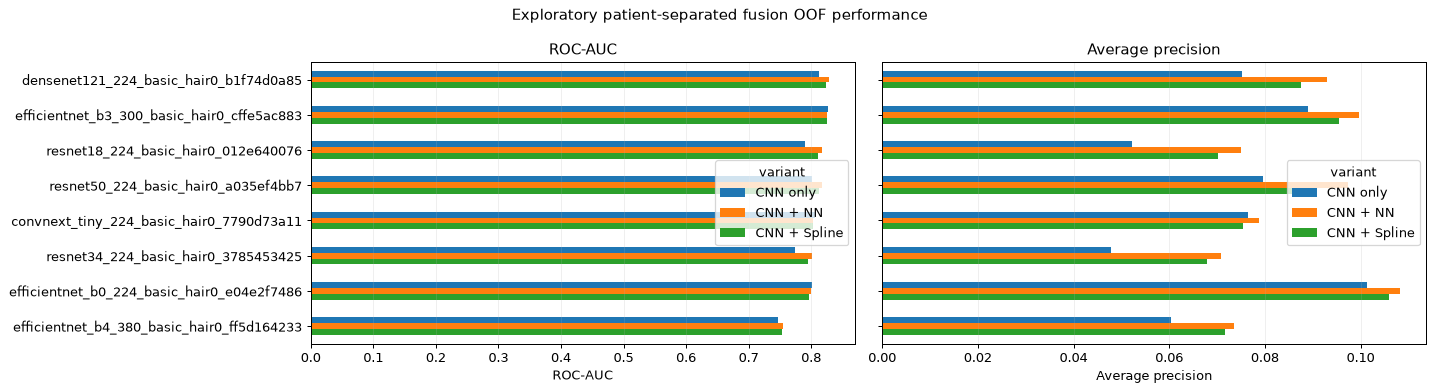

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, max(4, len(auc_summary) * 0.55)), sharey=True)
for ax, metric, label in zip(axes, ("ROC_AUC", "AP"), ("ROC-AUC", "Average precision")):
    values = comparison.pivot(index="image_run", columns="variant", values=metric).loc[auc_summary.index]
    values[["CNN only", "CNN + NN", "CNN + Spline"]].plot.barh(ax=ax)
    ax.set(title=label, xlabel=label, ylabel="")
    ax.grid(axis="x", alpha=0.2)
axes[0].invert_yaxis()
fig.suptitle("Exploratory patient-separated fusion OOF performance")
fig.tight_layout()
plt.show()

## 8. Final models and coefficients

Fit a final stacker for every CNN/metadata combination on all matched development
OOF rows, for future test inference only. Never use its in-sample predictions for
the reported metrics. Coefficients describe score combination, not causal importance.

In [8]:
final_models, coefficients = {}, []
for run, rows in fusion_data.items():
    final_models[run] = {}
    for variant, column in METADATA_VARIANTS.items():
        model = fit_final_fusion_model(rows, metadata_score_col=column,
            eps=LOGIT_EPS, random_state=RANDOM_STATE,
            source_paths={"image_oof": str(IMAGE_OOF_PATHS[run]),
                          "metadata_oof": str(METADATA_OOF_PATH),
                          "metadata_source_column": PRIMARY_METADATA_SCORE if variant == "NN" else "p_spline",
                          **{f"patient_fold_{i}": str(path) for i, path in enumerate(PATIENT_FOLD_PATHS, 1)}})
        final_models[run][variant] = model
        coefficients.append({"image_run": run, "metadata": variant,
                             **dict(zip(model.feature_names, model.estimator.coef_[0])),
                             "intercept": model.estimator.intercept_[0]})
coefficient_table = pd.DataFrame(coefficients)
display(coefficient_table.round(4))

,image_run,metadata,image_logit,metadata_logit,intercept
0,convnext_tiny_224_basic_hair0_7790d73a11,NN,0.9441,0.5402,0.4605
1,convnext_tiny_224_basic_hair0_7790d73a11,Spline,0.9465,0.4254,-0.0232
2,densenet121_224_basic_hair0_b1f74d0a85,NN,0.6872,0.5895,0.1973
3,densenet121_224_basic_hair0_b1f74d0a85,Spline,0.6881,0.4694,-0.3112
4,efficientnet_b0_224_basic_hair0_e04e2f7486,NN,0.7001,0.5802,0.2027
5,efficientnet_b0_224_basic_hair0_e04e2f7486,Spline,0.7048,0.4710,-0.2534
6,efficientnet_b3_300_basic_hair0_cffe5ac883,NN,0.8355,0.5100,0.3459
7,efficientnet_b3_300_basic_hair0_cffe5ac883,Spline,0.8419,0.4004,-0.1062
8,efficientnet_b4_380_basic_hair0_ff5d164233,NN,1.9330,0.5711,2.5430
9,efficientnet_b4_380_basic_hair0_ff5d164233,Spline,1.9621,0.4766,2.1899


## 9. Save outputs

Save each run's two OOF tables, final models and all three fold-specific stackers in separate directories, plus
shared rankings, metrics, provenance and merge audits. The old single-ResNet18
files are not outputs of this benchmark.

For later inference, load the selected joblib artifact and call
`predict_fusion_model(model, test_scores)`. Supply `image_score` and
`metadata_score` for NN, or `image_score` and `p_spline` for spline. Keep the
project module importable. Evaluate untouched test labels only once.

In [9]:
# Check every result before writing any benchmark artifacts.
for run, variants in fusion_oof.items():
    for oof in variants.values():
        validate_fusion_predictions(oof, fusion_data[run], split_maps)
METRICS_DIR.mkdir(parents=True, exist_ok=True)
for run, variants in fusion_oof.items():
    prediction_dir = P.predictions / "fusion" / run
    model_dir = P.models / "fusion" / run
    prediction_dir.mkdir(parents=True, exist_ok=True)
    model_dir.mkdir(parents=True, exist_ok=True)
    for variant, oof in variants.items():
        oof.to_csv(prediction_dir / f"fusion_{variant.lower()}_oof.csv", index=False)
        joblib.dump(final_models[run][variant], model_dir / f"fusion_image_metadata_{variant.lower()}.joblib")
        for fold, model in fold_models[run][variant].items():
            model.source_paths = dict(final_models[run][variant].source_paths)
            joblib.dump(model, model_dir / f"fusion_{variant.lower()}_fold_{fold}.joblib")
comparison.to_csv(METRICS_DIR / "fusion_all_models_comparison.csv", index=False)
fusion_ranking.to_csv(METRICS_DIR / "fusion_all_models_ranking.csv", index=False)
auc_summary.to_csv(METRICS_DIR / "fusion_all_models_auc_summary.csv")
metadata_comparison.to_csv(METRICS_DIR / "fusion_metadata_baselines.csv")
fold_metrics.to_csv(METRICS_DIR / "fusion_all_models_fold_metrics.csv", index=False)
coefficient_table.to_csv(METRICS_DIR / "fusion_all_models_coefficients.csv", index=False)
audit_table.to_csv(METRICS_DIR / "fusion_all_models_merge_counts.csv")
(METRICS_DIR / "fusion_all_models_merge_audits.json").write_text(
    json.dumps(merge_audits, indent=2), encoding="utf-8")
manifest = {"image_oof_paths": {run: str(path) for run, path in IMAGE_OOF_PATHS.items()},
            "metadata_oof_path": str(METADATA_OOF_PATH), "metadata_variants": METADATA_VARIANTS,
            "primary_metadata_source": PRIMARY_METADATA_SCORE,
            "patient_fold_paths": [str(path) for path in PATIENT_FOLD_PATHS],
            "logit_epsilon": LOGIT_EPS, "random_state": RANDOM_STATE, "threshold": THRESHOLD,
            "images": len(reference), "evaluation": "exploratory non-nested patient-separated OOF"}
(METRICS_DIR / "fusion_all_models_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(f"Saved {len(fusion_ranking)} OOF tables and final models in per-run fusion directories.")
print("Leaderboard:", METRICS_DIR / "fusion_all_models_ranking.csv")
print("Per-CNN summary:", METRICS_DIR / "fusion_all_models_auc_summary.csv")

Saved 16 OOF tables and final models in per-run fusion directories.
Leaderboard: C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma\results\metrics\fusion_all_models_ranking.csv
Per-CNN summary: C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma\results\metrics\fusion_all_models_auc_summary.csv


## 10. Interpretation

Compare each fusion with its own CNN baseline on the identical population.
Few melanoma cases, repeated images per patient, non-nested stacking and model
selection limit interpretation. Discrimination improvements do not guarantee
useful sensitivity at 0.5. Do not claim clinical significance.

In [10]:
for variant in ("CNN + NN", "CNN + Spline"):
    subset = fusion_ranking.loc[fusion_ranking.variant.eq(variant)]
    print(f"{variant}: ROC-AUC improved for {(subset.ROC_AUC_change > 0).sum()} of {len(subset)} CNNs.")
best = fusion_ranking.iloc[0]
print(f"Highest observed fusion: {best.image_run} / {best.variant}; ROC-AUC {best.ROC_AUC:.4f}")
print(f"AP {best.AP:.4f}; ROC-AUC change vs its CNN {best.ROC_AUC_change:+.4f}")
print(f"Sensitivity at threshold {THRESHOLD:g}: {best.Sensitivity:.4f}")
overall = comparison.iloc[0]
print(f"Highest overall: {overall.image_run} / {overall.variant}; ROC-AUC {overall.ROC_AUC:.4f}")
print("Exploratory ranking, not a fully nested or independent final test result.")

CNN + NN: ROC-AUC improved for 5 of 8 CNNs.
CNN + Spline: ROC-AUC improved for 5 of 8 CNNs.
Highest observed fusion: densenet121_224_basic_hair0_b1f74d0a85 / CNN + NN; ROC-AUC 0.8282
AP 0.0930; ROC-AUC change vs its CNN +0.0155
Sensitivity at threshold 0.5: 0.0000
Highest overall: densenet121_224_basic_hair0_b1f74d0a85 / CNN + NN; ROC-AUC 0.8282
Exploratory ranking, not a fully nested or independent final test result.
